In [1]:
################### Processing csv files to get points values! ########

from datetime import datetime, timedelta
import os
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
import requests
import sys
import geopandas as gpd
import pandas as pd
from shapely.geometry import MultiPoint
from shapely.geometry import Point
import fiona
import contextily as ctx
from datetime import datetime
from sklearn.ensemble import RandomForestClassifier
import simplekml
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from pyproj import Proj, transform
import ast
from pyproj import Transformer
import rasterio
from rasterio.features import geometry_mask
from rasterio.transform import from_origin
from rasterio.warp import calculate_default_transform, reproject
from rasterio.enums import Resampling

from scipy.ndimage import binary_fill_holes
from scipy.ndimage import convolve
from scipy.ndimage import distance_transform_edt
from affine import Affine
from scipy.spatial import KDTree
from rasterio.mask import mask
from rasterio.features import shapes
from shapely.geometry import shape
from simplekml import Kml
from osgeo import gdal

In [2]:
def count_non_nan_values(array):
        """Counts non-NaN values in an array while ignoring non-numeric elements."""
        # Filter to keep only numeric data (e.g., ints and floats)
        numeric_values = [x for x in array if isinstance(x, (int, float))] 
        # Convert to NumPy array and count non-NaN values
        return np.sum(~np.isnan(np.array(numeric_values, dtype=float)))
    
def data_prep(path, file, cutoff=0, direction=0, cutlon=0, sensor = 1):
    ####### filter the data with 015042 index ######
    df = pd.read_csv(path + file)
    df['ID'] = range(0, len(df))  # Generates IDs starting from 1
    
    if sensor == 0:
        training_data = df[['lat', 'lon', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7', 'ndmi', 'ndvi', 'savi', 'descriptio']].to_numpy()
    else:
        training_data = df[['lat', 'lon', 'SR_B1', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B7', 'ndmi', 'ndvi', 'savi', 'descriptio']].to_numpy()
    
    predictor = []
    target = []
    coord = []
    # Loop through each (1585, 10) array in training_data
    print('training data is:')
    #print(training_data)
    print(training_data.shape)
    #for array in training_data:
        # Get rows where the target is not 'TZ'
    mask = training_data[:, 11] != 'MZ'
    
    predictor.append(training_data[mask, 2:11])  # First 9 columns
    target.append(training_data[mask, 11])       # Target column
    coord.append(training_data[mask, :2])
    
    # Convert to NumPy arrays if desired
    predictor = np.array(predictor)
    target = np.array(target)
    coord = np.array(coord)
    
    X = predictor.reshape(-1, 9)  # Shape: (5 * 1585, 9)
    y = target.reshape(-1)        # Shape: (5 * 1585,)
    coord = coord.reshape(-1, 2)
    ### cleanse the data by removing nan ####
    valid_indices = []

    # Loop through each row and check for NaN in the first column
    for i in range(X.shape[0]):
        if not np.isnan(X[i, 0]):
            valid_indices.append(i)
    
    # Create new X and y with only valid rows
    X = X[valid_indices]
    y = y[valid_indices]
    coord = coord[valid_indices]

    print('the size of dataset is:')
    print(X.shape[0])

    if cutoff:
        if direction > 0: ### keep the eastern side
            masklon = coord[:, 1] > cutlon
        else:
            masklon = coord[:, 1] <= cutlon
    
        X = X[masklon]
        y = y[masklon]
        coord = coord[masklon]
    
        print('the size of lon filtered dataset is:')
        print(X.shape[0])
        #print(X)
    
    return X, y, coord

In [3]:
def model_train_test(X, y):
    # Initialize the RandomForestClassifier
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    
    # Fit the model to the reshaped data
    model.fit(X, y)
    
    # After training, the model can be used for predictions or evaluation
    y_pred = model.predict(X)
    
    # Calculate accuracy by comparing the predictions with the true labels (y)
    accuracy = model.score(X, y)
    
    print(f"Training and testing using the whole dataset, accuracy is: {accuracy * 100:.2f}%")

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model.fit(X_train, y_train)
    
    # Optionally, evaluate the model on the test set
    score = model.score(X_test, y_test)
    print(f"Testing using 20% of the whole dataset, accuracy is: {score*100:.2f}%")
    
    y_pred = model.predict(X_test)

    print("the number of elements for the prediction:")
    print(y_pred.shape[0])
    cm = confusion_matrix(y_test, y_pred, labels=['VZ', 'TZ', 'WZ'])
    
    # Plot the confusion matrix
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['VZ', 'TZ', 'WZ'])
    disp.plot(cmap='Blues', values_format='.0f')
    
    return accuracy

In [4]:
def model_across_years(X, y, X_test, y_test, coord_test):
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X, y)
    score = model.score(X_test, y_test)
    print(f"Testing across years, accuracy is: {score*100:.2f}%")
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=['VZ', 'TZ', 'WZ'])
    
    # Plot the confusion matrix
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['VZ', 'TZ', 'WZ'])
    disp.plot(cmap='Blues', values_format='.0f')

    incorrect_indices = y_test != y_pred  # Boolean array where predictions are wrong
    misclassified_data = coord_test[incorrect_indices]  # Coordinates of misclassified samples
    misclassified_y_true = y_test[incorrect_indices]  # True values of misclassified samples
    misclassified_y_pred = y_pred[incorrect_indices]  # Predicted values of misclassified samples
    
    # Output misclassified elements
    print("\nMisclassified samples:")
    # for i in range(len(misclassified_data)):
    #     print(f"Coord: {misclassified_data[i]}, Predicted: {misclassified_y_pred[i]}, True: {misclassified_y_true[i]}")
    return misclassified_data, misclassified_y_pred, misclassified_y_true

In [5]:
def export_mispred_to_kml(coord, mispred, output_path):
    # Define colors for each class
    color_mapping = {
        'VZ': 'ff00ff00',  # Green in KML color format (aabbggrr)
        'WZ': 'ff0000ff',  # Red
        'TZ': 'ff00ffff'   # Yellow
    }
    
    # Create a KML object
    kml = simplekml.Kml()
    
    # Iterate through the coordinates and mispred values
    for (lat, lon), label in zip(coord, mispred):
        # Add a point to the KML
        pnt = kml.newpoint(coords=[(lon, lat)])
        pnt.style.iconstyle.color = color_mapping[label]
        pnt.style.iconstyle.scale = 1.0  # Icon size
        pnt.name = label  # Label as the name of the point
    
    # Save the KML file
    kml.save(output_path)
    print(f"KML file saved at: {output_path}")

In [49]:
year = '2018'
X_2018, y_2018, coord = data_prep('/Users/bz294/Documents/WhiteZone/Points/KML/' + year + '/', 'median.csv', 0, 0, 0, 0) ## mixing 2022 Mar and 2023 Feb
X_2018 = X_2018.astype(float)
rows_with_nan = np.any(np.isnan(X_2018), axis=1)
indices_with_nan = np.where(rows_with_nan)[0]
print("indices with nan are:")
print(indices_with_nan)

training data is:
(1584, 12)
the size of dataset is:
1462
indices with nan are:
[]


Training and testing using the whole dataset, accuracy is: 100.00%
Testing using 20% of the whole dataset, accuracy is: 81.57%
the number of elements for the prediction:
293


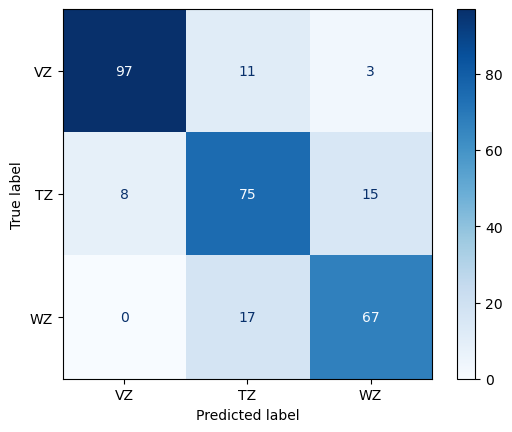

In [50]:
accuracy = model_train_test(X_2018, y_2018)

In [51]:
######### Regional Prediction ###################################
path = "/Users/bz294/Documents/WhiteZone/Points/KML/" + year + "/"
file = "MedianCompositeValues.csv"
region_df = pd.read_csv(path + file)

In [52]:
def extract_coordinates(row):
    try:
        # Parse the JSON-like string to a dictionary
        data = ast.literal_eval(row)
        coordinates = data['coordinates']
        lon = round(coordinates[0], 10)
        lat = round(coordinates[1], 10)
        return coordinates[0], coordinates[1]  # lon, lat
    except (ValueError, KeyError):
        return None, None  # Handle parsing errors gracefully

In [53]:
############ data prep #############

region_df['lon'], region_df['lat'] = zip(*region_df['.geo'].apply(extract_coordinates))
coordinates = region_df[['lon', 'lat']].to_numpy()
feature = region_df.iloc[:, 1:12].drop(region_df.columns[[7, 10]], axis=1).to_numpy()

rows_with_nan = np.any(np.isnan(feature), axis=1)

# Get indices of rows with NaN
indices_with_nan = np.where(rows_with_nan)[0]
print("indices with nan are:")
print(indices_with_nan)

feature_cleaned = np.delete(feature, indices_with_nan, axis=0)
coordinates_cleaned = np.delete(coordinates, indices_with_nan, axis=0)

transformer = Transformer.from_crs("EPSG:4326", "EPSG:32617", always_xy=True)

# Transform the coordinates
coord_utm = np.array([
    transformer.transform(lon, lat) for lon, lat in coordinates_cleaned
])

indices with nan are:
[]


In [54]:
# Define the threshold
threshold = 0.65

model = RandomForestClassifier(n_estimators=100, random_state=42)
    
# Fit the model to the reshaped data
model.fit(X_2018, y_2018)

# After training, the model can be used for predictions or evaluation
y_region = model.predict(feature_cleaned)
y_region_proba = model.predict_proba(feature_cleaned)
final_class_probs = np.max(y_region_proba, axis=1)


# Find indices where the predicted probability is less than the threshold
low_confidence_indices = final_class_probs < threshold

# Update y_region to 'TZ' where confidence is low
#y_region[low_confidence_indices] = 'TZ'

In [55]:
############ Output the shapefile ##############
filename = '/Volumes/Malonelab/Research/Whitezone/Result/' + year + '/output_points_' + year + '.shp'
geometry = [Point(xy) for xy in coord_utm]

# Create a GeoDataFrame
#gdf = gpd.GeoDataFrame({'y_region': final_class_probs}, geometry=geometry)
gdf = gpd.GeoDataFrame({'y_region': y_region}, geometry=geometry)

# Set the CRS to UTM 17N (EPSG:32617)
gdf.set_crs('EPSG:32617', inplace=True)

# Save to a shapefile
output_shapefile = filename  # Define your output shapefile path
gdf.to_file(output_shapefile)

print(f'Shapefile saved to: {output_shapefile}')

Shapefile saved to: /Volumes/Malonelab/Research/Whitezone/Result/2018/output_points_2018.shp


In [56]:
############# Points to Raster - Raster cell based method ##########
####################################################################
filename = '/Volumes/Malonelab/Research/Whitezone/Result/' + year + '/output_points_' + year + '.shp'
shapefile_path = filename
gdf = gpd.read_file(shapefile_path)
region_mapping = {'VZ': 1, 'WZ': 2, 'TZ': 3}
gdf['y_region_mapped'] = gdf['y_region'].map(region_mapping)

polygon_path = "/Users/bz294/Documents/WhiteZone/Points/Shapefiles/SEregion_reprojected_revise.shp" ## it is the utm projected
polygon_gdf = gpd.read_file(polygon_path)
geometries = [feature["geometry"] for feature in polygon_gdf.__geo_interface__["features"]]

xmin, ymin, xmax, ymax = gdf.total_bounds
pixel_size = 30  # Define the pixel size
cols = int((xmax - xmin) / pixel_size)
rows = int((ymax - ymin) / pixel_size)
transform = from_origin(xmin, ymax, pixel_size, pixel_size)
# Get coordinates and y_region values
coords = np.array([(point.x, point.y) for point in gdf.geometry])
values = gdf['y_region_mapped'].values
#values = gdf['y_region'].values

In [57]:
# Build a KDTree for nearest-neighbor search
tree = KDTree(coords)

# Create an empty raster
raster = np.empty((rows, cols), dtype=np.float32)
raster.fill(np.nan)

# Iterate over the raster grid
x_coords = np.linspace(xmin + pixel_size / 2, xmax - pixel_size / 2, cols)
y_coords = np.linspace(ymax - pixel_size / 2, ymin + pixel_size / 2, rows)
for i, y in enumerate(y_coords):
    for j, x in enumerate(x_coords):
        # Find the nearest point
        _, idx = tree.query((x, y))
        raster[i, j] = values[idx]

# Save the raster
output_raster_path = "output_raster.tif"
with rasterio.open(
    output_raster_path,
    'w',
    driver='GTiff',
    height=rows,
    width=cols,
    count=1,
    dtype=raster.dtype,
    crs=gdf.crs.to_string(),
    transform=transform
) as dst:
    dst.write(raster, 1)

print(f"Raster saved to {output_raster_path}")

Raster saved to output_raster.tif


In [58]:
######### Read it back and filter the outside areas #########
with rasterio.open(output_raster_path) as src:
    out_image, out_transform = mask(src, geometries, crop=False) ## mask out based on the SE region shapefile
    out_meta = src.meta

# Update metadata to account for changes
out_meta.update({"height": out_image.shape[1], "width": out_image.shape[2], "transform": out_transform})

output_raster_path = "raster_" + year + ".tif"
# Save the masked raster
with rasterio.open(output_raster_path, "w", **out_meta) as dst:
    dst.write(out_image)

print(f"Masked raster saved to {output_raster_path}")

Masked raster saved to raster_2018.tif


In [ ]:
##################### Convert to KMZ ##############################
# File paths
input_raster_path = 'output_raster_reproj.tif'
output_raster_path = 'output_wgs84.tif'

# Open the original raster
with rasterio.open(input_raster_path) as src:
    # Calculate the transformation and new dimensions for EPSG:4326
    transform, width, height = calculate_default_transform(
        src.crs,  # Current CRS (EPSG:32617)
        'EPSG:4326',  # Target CRS (EPSG:4326)
        src.width, 
        src.height, 
        *src.bounds
    )
    
    # Reproject the raster to EPSG:4326
    kwargs = src.meta.copy()
    kwargs.update({
        'crs': 'EPSG:4326',
        'transform': transform,
        'width': width,
        'height': height
    })
    
    # Write the reprojecated raster to a new file
    with rasterio.open(output_raster_path, 'w', **kwargs) as dst:
        for i in range(1, src.count + 1):
            reproject(
                source=rasterio.band(src, i),
                destination=rasterio.band(dst, i),
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=transform,
                dst_crs='EPSG:4326',
                resampling=Resampling.nearest
            )

print(f"Reprojected raster saved to {output_raster_path}")

In [ ]:
##################### Convert raster to kml ##############
output_kml_path = 'output_kml.kml'
polygon_path = "/Users/bz294/Documents/WhiteZone/Points/Shapefiles/SEregion_reprojected.shp"

with rasterio.open(output_raster_path) as reprojected_src:
    reprojected_data = reprojected_src.read(1)  # Read the first band
    reprojected_transform = reprojected_src.transform

# Step 1: Read the polygon shapefile
gdf = gpd.read_file(polygon_path)

# Step 3: Initialize KML
kml = simplekml.Kml()

# Step 4: Iterate through each geometry in the GeoDataFrame and add to KML
for _, row in gdf.iterrows():
    # Create a new polygon in KML
    poly = kml.newpolygon(name=str(row['id']))  # You can use any column as name
    poly.outerboundaryis = list(row['geometry'].exterior.coords)
    
    # Optional: Style the polygons with color (e.g., red)
    poly.style.polystyle.color = '7fff0000'  # Format is aabbggrr (red with some transparency)

kml.save(output_kml_path)
print(f"KML file saved to: {output_kml_path}")

In [ ]:
unique_values = np.unique(out_image)
print(f"Unique values in the masked raster: {unique_values}")

print(f"Masked raster saved to {output_raster_path}")

In [ ]:
################### Reproject the polygon to the UTM ########
points_gdf = gpd.read_file('/Volumes/Malonelab/Research/Whitezone/Result/1985/output_points_1985.shp')

# Load the polygon shapefile
polygon_gdf = gpd.read_file('/Users/bz294/Documents/WhiteZone/Points/Shapefiles/SEregion.shp')

# Check the CRS of both shapefiles
points_crs = points_gdf.crs
polygon_crs = polygon_gdf.crs

print(f"Points CRS: {points_crs}")
print(f"Polygon CRS: {polygon_crs}")

# Verify if they share the same CRS
if points_crs == polygon_crs:
    print("The shapefiles share the same coordinate system.")
else:
    print("The shapefiles have different coordinate systems.")
    
# Get the CRS of the points shapefile
points_crs = points_gdf.crs

# Reproject the polygon shapefile to match the points CRS
polygon_gdf_reprojected = polygon_gdf.to_crs(points_crs)

# Save the reprojected polygon shapefile
reprojected_path = '/Users/bz294/Documents/WhiteZone/Points/Shapefiles/SEregion_reprojected.shp'
polygon_gdf_reprojected.to_file(reprojected_path)

print(f"Polygon shapefile reprojected and saved to: {reprojected_path}")

In [ ]:
###################### Supplementary #############################

In [ ]:
target_point = np.array([550941, 2791856])

# Calculate Euclidean distances
distances = np.linalg.norm(coord_utm - target_point, axis=1)

# Find the index of the row with the minimum distance
closest_index = np.argmin(distances)

# Get the closest row and its distance
closest_row = coord_utm[closest_index]
closest_distance = distances[closest_index]

# Output results
print(f"Closest row: {closest_row}")
print(f"Index: {closest_index}")
print(f"Distance: {closest_distance}")

In [ ]:
for col in range(X_2013.shape[1]):
    col_max = X_2013[:, col].max()
    col_min = X_2013[:, col].min()
    print(f"Column {col + 1}: Max = {col_max}, Min = {col_min}")

In [ ]:
# Check for rows with all elements zero
rows_with_all_zeros = np.all(X_2013 == 0, axis=1)

# Get indices of rows with all zeros
indices_with_all_zeros = np.where(rows_with_all_zeros)[0]

# Output results
if indices_with_all_zeros.size > 0:
    print(f"Rows with all elements as zero: {indices_with_all_zeros}")
else:
    print("No rows with all elements as zero.")